In [1]:
from olist.data import Olist

data = Olist().get_data()

print(data.keys())

dict_keys(['geolocation', 'order_payments', 'order_reviews', 'sellers', 'products', 'product_category_name_translation', 'order_items', 'orders', 'customers'])


In [2]:
import pandas as pd

sellers = data['sellers']
order_items = data['order_items']

print("Seller sayısı:", sellers.shape[0])
print("Sipariş kalemi sayısı:", order_items.shape[0])

display(sellers.head())
display(order_items.head())

Seller sayısı: 3095
Sipariş kalemi sayısı: 112650


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


# CEO-Request Challenge

## 1. Sorun Tanımının Özeti

❓ **Olist kârını nasıl artırabilir?** ❓

### P&L Kuralları

#### Revenues  (Gelirler )
**Sales fees:** Olist, teslim edilen her order’ın ürün fiyatı üzerinden (freight hariç) **%10 pay** alır.  
**Subscription fees:** Olist, seller başına ayda **80 BRL** ücret alır.

#### Costs (Maliyetler)
Kötü review’lara (<= 3 stars) sahip orders için _tahmini_ **reputation costs**  

💡 Uzun vadede kötü customer experience iş açısından sonuçlara yol açar: düşük tekrar satın alma oranı, anında customer support maliyeti, refunds veya olumsuz word of mouth iletişimi. Her kötü review için parasal bir cost varsayımı yapıyoruz:

```python
# review_score: cost(BRL)
{'1 star': 100
'2 stars': 50
'3 stars': 40
'4 stars': 0
'5 stars': 0}
```

**IT costs:** Olist'in total cumulated IT Costs değeri, platforma şimdiye kadar katılmış toplam seller sayısının karekökü ile, şimdiye kadar satılmış toplam birikimli item sayısının karekökü oranında ölçeklenir.

$IT\_costs = \alpha * \sqrt{n\_sellers} + \beta * \sqrt{n\_items}$  

Olist'in data team’i bize bu scaling parameter’ları için şu değerleri verdi:
- $\alpha = 3157.27$
- $\beta = 978.23$

💡 Yönetilen seller sayısı da, sales transaction sayısı da IT systems için maliyetlidir.
💡 Ancak karekök kullanımı scale-effects’i gösterir: IT-system’ler büyüdükçe daha verimli olma eğilimindedir.
💡 Alpha > Beta olması, Olist’in çok item satan az sayıda seller ile çalıştığında, bunun tersi senaryoya göre daha düşük IT Cost’a sahip olduğu anlamına gelir.

1000 sellers ve toplam 100 items satışıyla toplam IT cost 109,624 BRL olur

100 sellers ve toplam 1000 items satışıyla toplam IT cost 62,507 BRL olur

Son olarak, IT department size marketplace’in kuruluşundan bu yana birikmiş IT costs toplamının 500,000 BRL olduğunu da iletti.

Şimdi, bu IT cost formülünü biraz daha iyi anlamak için bir simulation çalıştıralım. Kod üzerinde zaman harcamanıza gerek yok, sadece ortaya çıkan chart’lara bakın.

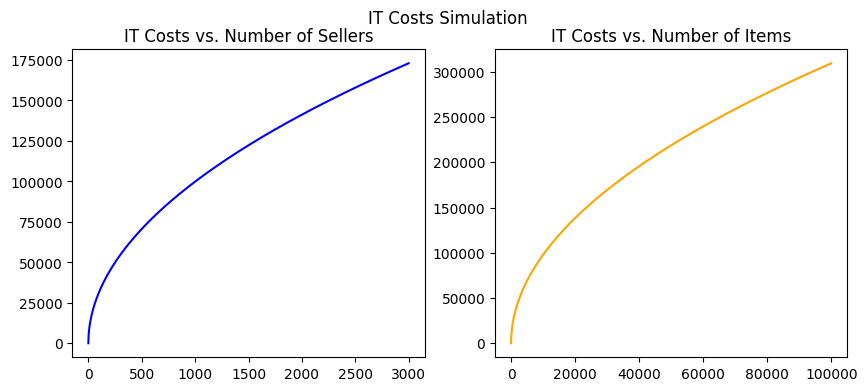

In [3]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

alpha = 3157.27
beta = 978.23

x_sellers = np.arange(3_000)
y_it_costs_sellers = alpha * x_sellers ** 0.5

x_items = np.arange(100_000)
y_it_costs_items = beta * x_items ** 0.5

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x_sellers, y_it_costs_sellers, label='IT costs per seller', color='blue')
plt.title('IT Costs vs. Number of Sellers')
plt.subplot(1, 2, 2)
plt.plot(x_items, y_it_costs_items, label='IT costs per item', color='orange')
plt.title('IT Costs vs. Number of Items')
plt.suptitle('IT Costs Simulation');

### Key Findings, so far

- `wait_time`, düşük review_score’ların arkasındaki en önemli faktördür.  
- `wait_time`, seller’ın `delay_to_carrier` süresi + `carrier_delivery_time` toplamından oluşur.  
- Carrier’ın delivery time’ı Olist’in doğrudan kontrolünde olmadığı için, bunu iyileştirmek hızlı kazanım sağlayacak bir öneri değildir.  
- Buna karşılık, daha iyi bir `seller` seçimi `delay_to_carrier` değerini olumlu şekilde etkileyebilir ve Olist üzerindeki kötü `review_scores` sayısını azaltabilir.  
- Kötü review’lardaki yorumlar, bazılarının seller’dan veya bizzat üründen kaynaklandığını göstermiştir.

💡 Aşağıdaki bölüm 2’deki guided seller analysis ile başlamanızı öneririz.

💪 Ancak bölüm 3 ile başka hipotezleri araştırmakta özgürsünüz.

## 2. Olist, performansları düşük satıcıları pazarından çıkarmalı mı? 🕵🏻
*(önerilen)*

Olist’in marketplace’inden en kötü seller’ları çıkarmanın etkisini analiz etmek için bir **what-if analysis** yapacağız.

👉 **Olist bu seller’ları en baştan hiç kabul etmemiş olsaydı ne olurdu?**  

*(Gerçekte, kimin iyi seller olduğunu önceden bilmek zordur, ancak bu yaklaşımla başlayıp daha sonra iterasyon yapacağız.)*


### 2.1 Veri Hazırlama

Her bir `seller_id` için, başlangıçtan itibaren kümülatif olarak hesaplayın:
- seller’ın getirdiği `revenues`
- seller’ın kötü review’larına bağlı `review_costs`
- ortaya çıkan `profits` (revenues - costs)

👉 İhtiyacınız olan DataFrame’i oluşturmak için adım adım bir strateji yazın.

⚠️ **Sıfırdan başlamayın, mevcut package’ınızı güncelleyin!** 😉

**Çözüm, notebook’a yeni kod yazmakta değil — `.py` dosyalarınızdaki kodu değiştirmektedir.**

`olist` package’ınız içindeki `Seller` class’ından başlayarak:

`get_training_data` method’unu düzenleyin; döndürdüğü DataFrame şu alanları içermeli:
- `revenues`: subscription + sales fees toplamı  
- `cost_of_reviews`: kötü review’lara bağlı toplam cost  
- `profits`: `revenues` - `cost_of_reviews`

`cost_of_reviews` için önce başka bir method’u değiştirmeniz gerekecek. Bununla ilgili olan method hangisi?

In [4]:
from olist.seller import Seller
import inspect

print(inspect.getsource(Seller))

class Seller:
    def __init__(self):
        # Import data only once
        olist = Olist()
        self.data = olist.get_data()
        self.order = Order()

    def get_seller_features(self):
        """
        Returns a DataFrame with:
        'seller_id', 'seller_city', 'seller_state'
        """
        sellers = self.data['sellers'].copy(
        )  # Make a copy before using inplace=True so as to avoid modifying self.data
        sellers.drop('seller_zip_code_prefix', axis=1, inplace=True)
        sellers.drop_duplicates(
            inplace=True)  # There can be multiple rows per seller
        return sellers

    def get_seller_delay_wait_time(self):
        """
        Returns a DataFrame with:
        'seller_id', 'delay_to_carrier', 'wait_time'
        """
        # Get data
        order_items = self.data['order_items'].copy()
        orders = self.data['orders'].query("order_status=='delivered'").copy()

        ship = order_items.merge(orders, on='order_id')

        

In [5]:
from olist.seller import Seller

methods = [
    method for method in dir(Seller)
    if not method.startswith("_")
]

print(methods)

['get_active_dates', 'get_quantity', 'get_review_score', 'get_sales', 'get_seller_delay_wait_time', 'get_seller_features', 'get_training_data']


In [6]:
import inspect
from olist.seller import Seller

print(inspect.getsource(Seller.get_review_score))
print(inspect.getsource(Seller.get_training_data))

    def get_review_score(self):
        """
        Returns a DataFrame with:
        'seller_id', 'share_of_five_stars',
        'share_of_one_stars', 'review_score'
        """
        from olist.data import Olist

        data = Olist().get_data()

        reviews = data['order_reviews']
        items = data['order_items']

        seller_orders = items[
            ['seller_id', 'order_id']
        ].drop_duplicates()

        merged = seller_orders.merge(
            reviews[['order_id', 'review_score']],
            on='order_id',
            how='inner'
        )

        result = merged.groupby('seller_id').agg(
            share_of_five_stars=(
                'review_score',
                lambda x: (x == 5).mean()
            ),
            share_of_one_stars=(
                'review_score',
                lambda x: (x == 1).mean()
            ),
            review_score=('review_score', 'mean')
        ).reset_index()

        return result

    def get_training_data(sel

In [7]:
import olist.seller

print(olist.seller.__file__)

/home/turke/code/data-context-and-setup/olist/seller.py


In [11]:
import py_compile

py_compile.compile(
    "/home/turke/code/data-context-and-setup/olist/seller.py",
    doraise=True
)

print("Syntax OK")

Syntax OK


In [10]:
path = "/home/turke/code/data-context-and-setup/olist/seller.py"

with open(path, "r") as f:
    lines = f.readlines()

for i in range(145, min(200, len(lines))):
    print(f"{i+1}: {lines[i]}", end="")

146: 
147:     reviews = data['order_reviews']
148:     items = data['order_items']
149: 
150:     seller_orders = items[
151:         ['seller_id', 'order_id']
152:     ].drop_duplicates()
153: 
154:     merged = seller_orders.merge(
155:         reviews[['order_id', 'review_score']],
156:         on='order_id',
157:         how='inner'
158:     )
159: 
160:     review_costs = {
161:         1: 100,
162:         2: 50,
163:         3: 40,
164:         4: 0,
165:         5: 0
166:     }
167: 
168:     merged['review_cost'] = (
169:         merged['review_score'].map(review_costs)
170:     )
171: 
172:     result = merged.groupby('seller_id').agg(
173:         share_of_five_stars=(
174:             'review_score',
175:             lambda x: (x == 5).mean()
176:         ),
177:         share_of_one_stars=(
178:             'review_score',
179:             lambda x: (x == 1).mean()
180:         ),
181:         review_score=(
182:             'review_score',)
183: 
184:     def get_trainin

In [12]:
from olist.seller import Seller

seller_data = Seller().get_training_data()

print(
    seller_data[
        ['seller_id', 'revenues', 'cost_of_reviews', 'profits']
    ].head()
)

AttributeError: 'Seller' object has no attribute 'get_training_data'

In [13]:
path = "/home/turke/code/data-context-and-setup/olist/seller.py"

with open(path, "r") as f:
    lines = f.readlines()

for i in range(125, min(220, len(lines))):
    print(f"{i+1}: {lines[i]}", end="")

126:         result['quantity_per_order'] = result['quantity'] / result['n_orders']
127:         return result
128: 
129:     def get_sales(self):
130:         """
131:         Returns a DataFrame with:
132:         'seller_id', 'sales'
133:         """
134:         return self.data['order_items'][['seller_id', 'price']]\
135:             .groupby('seller_id')\
136:             .sum()\
137:             .rename(columns={'price': 'sales'})
138: 
139: def get_review_score(self):
140:     """
141:     Returns seller review statistics and review costs.
142:     """
143:     from olist.data import Olist
144: 
145:     data = Olist().get_data()
146: 
147:     reviews = data['order_reviews']
148:     items = data['order_items']
149: 
150:     seller_orders = items[
151:         ['seller_id', 'order_id']
152:     ].drop_duplicates()
153: 
154:     merged = seller_orders.merge(
155:         reviews[['order_id', 'review_score']],
156:         on='order_id',
157:         how='inner'
158:     )
159

In [14]:
import py_compile
import importlib
import olist.seller

py_compile.compile(olist.seller.__file__, doraise=True)
importlib.reload(olist.seller)

print("Syntax OK")
print("get_training_data:", hasattr(olist.seller.Seller, "get_training_data"))

[autoreload of olist.seller failed: Traceback (most recent call last):
  File "/home/turke/.pyenv/versions/workintech/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 276, in check
    superreload(m, reload, self.old_objects)
  File "/home/turke/.pyenv/versions/workintech/lib/python3.12/site-packages/IPython/extensions/autoreload.py", line 475, in superreload
    module = reload(module)
             ^^^^^^^^^^^^^^
  File "/home/turke/.pyenv/versions/3.12.9/lib/python3.12/importlib/__init__.py", line 131, in reload
    _bootstrap._exec(spec, module)
  File "<frozen importlib._bootstrap>", line 866, in _exec
  File "<frozen importlib._bootstrap_external>", line 995, in exec_module
  File "<frozen importlib._bootstrap_external>", line 1133, in get_code
  File "<frozen importlib._bootstrap_external>", line 1063, in source_to_code
  File "<frozen importlib._bootstrap>", line 488, in _call_with_frames_removed
  File "/home/turke/code/data-context-and-setup/olist/seller.py

PyCompileError: Sorry: IndentationError: unindent does not match any outer indentation level (seller.py, line 193)

In [15]:
from pathlib import Path

path = Path("/home/turke/code/data-context-and-setup/olist/seller.py")

lines = path.read_text().splitlines(keepends=True)

# Önce yedek oluştur
backup = path.with_suffix(".py.bak")
backup.write_text("".join(lines))

# get_review_score metodunun girintisini düzelt
for i in range(138, 191):
    lines[i] = "    " + lines[i].lstrip("\t") if i == 138 else "    " + lines[i]

# Tab karakterlerini 4 boşluğa dönüştür
lines = [line.expandtabs(4) for line in lines]

path.write_text("".join(lines))

import py_compile
py_compile.compile(str(path), doraise=True)

print("Syntax OK")

Syntax OK


In [16]:
import importlib
import olist.seller

importlib.reload(olist.seller)

Seller = olist.seller.Seller

print("get_review_score:", hasattr(Seller, "get_review_score"))
print("get_training_data:", hasattr(Seller, "get_training_data"))

seller_data = Seller().get_training_data()

print(seller_data[
    ['seller_id', 'revenues', 'cost_of_reviews', 'profits']
].head())

get_review_score: True
get_training_data: True


KeyError: 'cost_of_reviews'

In [17]:
import importlib
import olist.seller

importlib.reload(olist.seller)

seller_data = olist.seller.Seller().get_training_data()

display(
    seller_data[
        ['seller_id', 'revenues', 'cost_of_reviews', 'profits']
    ].head()
)

,seller_id,revenues,cost_of_reviews,profits
0,3442f8959a84dea7ee197c632cb2df15,341.870,140.0,201.870
1,d1b65fc7debc3361ea86b5f14c68d2e2,2290.307,240.0,2050.307
2,ce3ad9de960102d0677a81f5d0bb7b2d,15.800,0.0,15.800
3,c0f3eea2e14555b6faeea3dd58c1b1c3,7.999,0.0,7.999
4,51a04a8a6bdcb23deccc82b0b80742cf,16.799,100.0,-83.201


### 2.2 IT Maliyetleri Hariç Varsayım Analizi

sellers_sorted = seller_data.sort_values(
    by='profits',
    ascending=False
).reset_index(drop=True)

sellers_sorted['cumulative_profits'] = (
    sellers_sorted['profits'].cumsum()
)

display(
    sellers_sorted[
        ['seller_id', 'profits', 'cumulative_profits']
    ].head(10)
)

In [18]:
sellers_sorted = seller_data.sort_values(
    by='profits',
    ascending=False
).reset_index(drop=True)

sellers_sorted['cumulative_profits'] = (
    sellers_sorted['profits'].cumsum()
)

display(
    sellers_sorted[
        ['seller_id', 'profits', 'cumulative_profits']
    ].head(10)
)

,seller_id,profits,cumulative_profits
0,53243585a1d6dc2643021fd1853d8905,18067.605,18067.605
1,7e93a43ef30c4f03f38b393420bc753a,14623.187,32690.792
2,fa1c13f2614d7b5c4749cbc52fecda94,14494.203,47184.995
3,edb1ef5e36e0c8cd84eb3c9b003e486d,7288.455,54473.450
4,46dc3b2cc0980fb8ec44634e21d2718e,7151.119,61624.569
5,4869f7a5dfa277a7dca6462dcf3b52b2,6907.263,68531.832
6,ccc4bbb5f32a6ab2b7066a4130f114e3,6780.462,75312.294
7,5dceca129747e92ff8ef7a997dc4f8ca,6325.553,81637.847
8,17f51e7198701186712e53a39c564617,5641.900,87279.747
9,e882b2a25a10b9c057cc49695f222c19,5425.754,92705.501


In [19]:
optimal_index = sellers_sorted['cumulative_profits'].idxmax()

optimal_n_sellers = optimal_index + 1

max_profit = sellers_sorted.loc[
    optimal_index, 'cumulative_profits'
]

total_sellers = len(sellers_sorted)

sellers_to_remove = total_sellers - optimal_n_sellers

print("Toplam satıcı:", total_sellers)
print("Tutulması gereken satıcı:", optimal_n_sellers)
print("Çıkarılması gereken satıcı:", sellers_to_remove)
print("Maksimum kâr (BRL):", round(max_profit, 2))

Toplam satıcı: 2970
Tutulması gereken satıcı: 2599
Çıkarılması gereken satıcı: 371
Maksimum kâr (BRL): 1494148.74


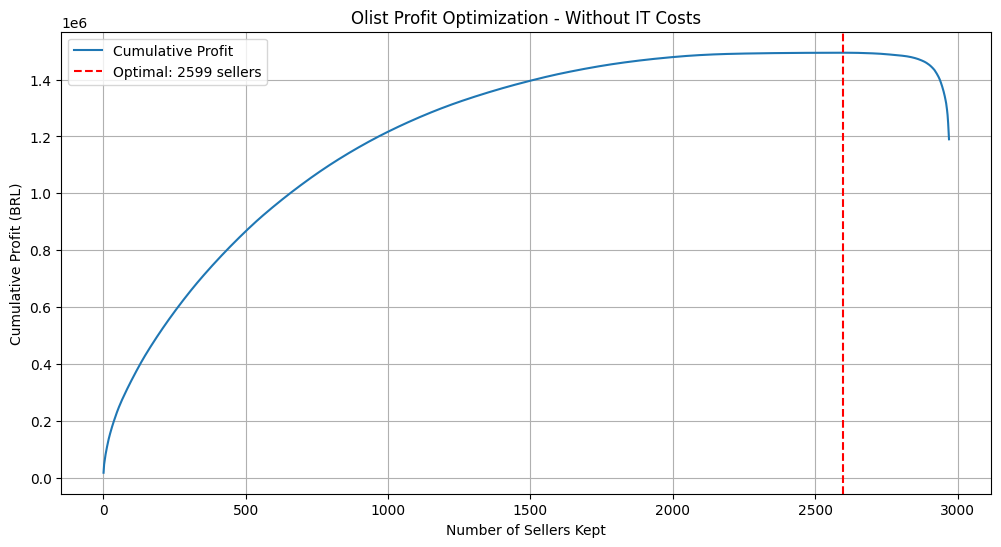

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(sellers_sorted) + 1),
    sellers_sorted['cumulative_profits'],
    label='Cumulative Profit'
)

plt.axvline(
    x=optimal_n_sellers,
    color='red',
    linestyle='--',
    label=f'Optimal: {optimal_n_sellers} sellers'
)

plt.xlabel('Number of Sellers Kept')
plt.ylabel('Cumulative Profit (BRL)')
plt.title('Olist Profit Optimization - Without IT Costs')
plt.legend()
plt.grid(True)
plt.show()

In [21]:
import numpy as np

def compute_it_cost(n_sellers, n_items):
    alpha = 3157.27
    beta = 978.23

    return (
        alpha * np.sqrt(n_sellers)
        + beta * np.sqrt(n_items)
    )

print("Quantity columns:")
print(seller_data.columns.tolist())

print("\nExample IT cost:")
print(round(compute_it_cost(100, 1000), 2))

Quantity columns:
['seller_id', 'seller_city', 'seller_state', 'delay_to_carrier', 'wait_time', 'date_first_sale', 'date_last_sale', 'months_on_olist', 'n_orders', 'quantity', 'quantity_per_order', 'sales', 'share_of_five_stars', 'share_of_one_stars', 'review_score', 'cost_of_reviews', 'revenues', 'profits']

Example IT cost:
62507.05


In [22]:
# Birikimli ürün sayısı
sellers_sorted['cumulative_quantity'] = (
    sellers_sorted['quantity'].cumsum()
)

# Tutulan satıcı sayısı
sellers_sorted['n_sellers'] = (
    np.arange(1, len(sellers_sorted) + 1)
)

# IT maliyetleri
sellers_sorted['it_costs'] = compute_it_cost(
    sellers_sorted['n_sellers'],
    sellers_sorted['cumulative_quantity']
)

# IT maliyetleri sonrası net kâr
sellers_sorted['net_profits'] = (
    sellers_sorted['cumulative_profits']
    - sellers_sorted['it_costs']
)

# Maksimum net kârın bulunduğu satır
optimal_it_index = sellers_sorted['net_profits'].idxmax()

optimal_it_sellers = int(
    sellers_sorted.loc[optimal_it_index, 'n_sellers']
)

max_net_profit = sellers_sorted.loc[
    optimal_it_index, 'net_profits'
]

print("Toplam satıcı:", len(sellers_sorted))
print("Tutulacak satıcı:", optimal_it_sellers)
print("Çıkarılacak satıcı:", len(sellers_sorted) - optimal_it_sellers)
print("Maksimum net kâr (BRL):", round(max_net_profit, 2))

Toplam satıcı: 2970
Tutulacak satıcı: 2118
Çıkarılacak satıcı: 852
Maksimum net kâr (BRL): 1090497.54


👉 Gerçek analizi yapma zamanı. İlk olarak bunu IT costs **dahil etmeden** gerçekleştireceğiz.

Adımlarımız:  

1️⃣ Sellers verisini load edin ve profits değerine göre azalan şekilde sıralayın.

2️⃣ Cumulative değerleri hesaplayın:
   - Her satır için cumulative revenues hesaplayın.
   - Her satır için cumulative profits hesaplayın.
   - Her satır için cumulative items sold hesaplayın.

   Pandas ile cumulative sum nasıl hesaplanır, araştırın.

3️⃣ Sonuçlarınızı plot edin ve analiz edin. Pandas’ın `.plot()` method’unu kullanın.

4️⃣ Profits’e göre tutulması gereken optimum seller sayısını belirleyin. (İpucu: `np.argmax` araştırın). Bu kararın etkisi ne olurdu:
   - Net profit (IT costs dahil etmediğimiz için IT costs öncesi)?
   - Total revenues?
   - Seller sayısı?
   - Satılan item sayısı?

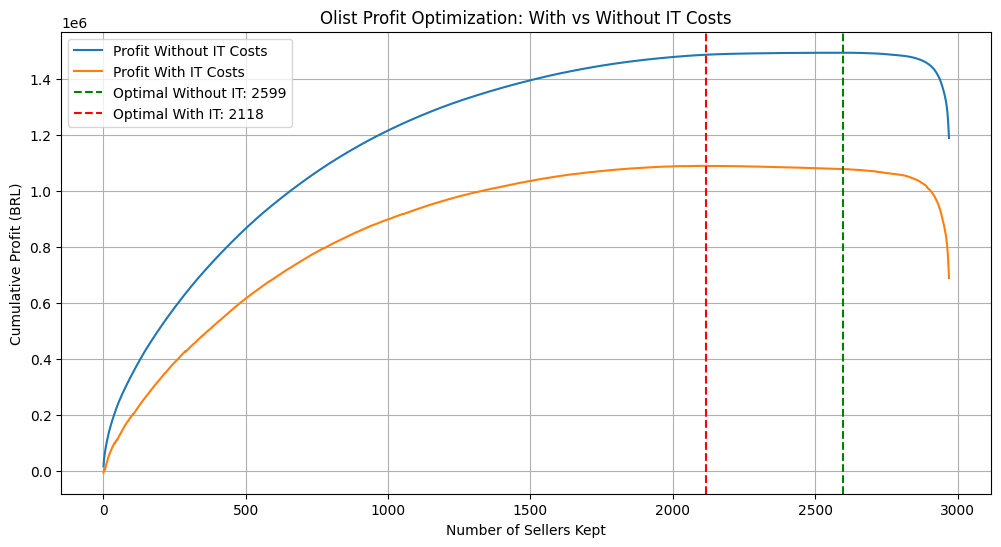

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    sellers_sorted['n_sellers'],
    sellers_sorted['cumulative_profits'],
    label='Profit Without IT Costs'
)

plt.plot(
    sellers_sorted['n_sellers'],
    sellers_sorted['net_profits'],
    label='Profit With IT Costs'
)

plt.axvline(
    x=optimal_n_sellers,
    color='green',
    linestyle='--',
    label=f'Optimal Without IT: {optimal_n_sellers}'
)

plt.axvline(
    x=optimal_it_sellers,
    color='red',
    linestyle='--',
    label=f'Optimal With IT: {optimal_it_sellers}'
)

plt.xlabel('Number of Sellers Kept')
plt.ylabel('Cumulative Profit (BRL)')
plt.title('Olist Profit Optimization: With vs Without IT Costs')

plt.legend()
plt.grid(True)
plt.show()

### 2.3 IT maliyetleri ile varsayımsal analiz (İsteğe bağlı)

👉 Bu kez IT costs dahil edilerek gerçek analizi yapma zamanı.

Adımlarımız şunlar:  

1️⃣ İki parametreye göre IT costs hesaplayan bir function yazın: seller sayısı ve item sayısı. Temelde matematiksel formülü Python kullanarak yazmanız yeterli.

2️⃣ Sellers verisini load edin ve (IT costs öncesi) kârlarına göre azalan şekilde sıralayın.

3️⃣ Cumulative değerleri hesaplayın (önceki kodu yeniden kullanın):
   - Her satır için cumulative revenues hesaplayın.
   - Her satır için cumulative profits hesaplayın.
   - Her satır için toplam satılan item miktarının cumulative değerini hesaplayın.  

4️⃣ IT costs etkisini hesaplayın:
   - 1️⃣. adımda yazdığınız function’ı kullanarak her satır için cumulative IT cost ekleyin.
   - IT costs sonrası net profit’i hesaplayın.

5️⃣ Sonuçlarınızı plot edin ve analiz edin.

6️⃣ Bu kez IT costs sonrası kârları baz alarak tutulması gereken optimum seller sayısını belirleyin. Bu kararın etkisi ne olurdu:
   - IT costs sonrası net profit?
   - IT costs öncesi net profit?
   - IT costs?
   - Total revenues?
   - Seller sayısı?
   - Satılan item sayısı?

Analizinizde IT costs ne kadar önemliydi?


In [24]:
# IT maliyetlerinin optimum satıcı sayısına etkisi
seller_difference = optimal_n_sellers - optimal_it_sellers

# IT dahil optimum noktadaki maliyet
optimal_it_cost = sellers_sorted.loc[
    optimal_it_index, 'it_costs'
]

# IT dahil optimum noktadaki IT öncesi kar
profit_before_it = sellers_sorted.loc[
    optimal_it_index, 'cumulative_profits'
]

print("IT hariç optimum satıcı:", optimal_n_sellers)
print("IT dahil optimum satıcı:", optimal_it_sellers)
print("Optimum satıcı sayısındaki fark:", seller_difference)

print("\nIT dahil optimum noktada:")
print("IT öncesi kâr:", round(profit_before_it, 2), "BRL")
print("IT maliyeti:", round(optimal_it_cost, 2), "BRL")
print("IT sonrası net kâr:", round(max_net_profit, 2), "BRL")

print(
    "IT maliyetinin IT öncesi kâra oranı:",
    round(optimal_it_cost / profit_before_it * 100, 2),
    "%"
)

IT hariç optimum satıcı: 2599
IT dahil optimum satıcı: 2118
Optimum satıcı sayısındaki fark: 481

IT dahil optimum noktada:
IT öncesi kâr: 1487038.15 BRL
IT maliyeti: 396540.62 BRL
IT sonrası net kâr: 1090497.54 BRL
IT maliyetinin IT öncesi kâra oranı: 26.67 %


In [ ]:
Impact of IT Costs on Profitability

IT costs have a significant impact on Olist's profitability and seller optimization strategy.

Without IT costs, the optimal number of sellers is 2,599.

With IT costs, the optimal number decreases to 2,118, a difference of 481 sellers.

At the new optimal point, IT costs amount to 396,540.62 BRL, representing 26.67% of profit before IT expenses.

The maximum net profit after IT costs is 1,090,497.54 BRL.

Conclusion: IT costs are a major factor in Olist's profitability. Including these costs changes the optimal seller count substantially, demonstrating the importance of considering operational expenses when making strategic decisions.

## 3. Diğer Yaklaşımları Araştırın 🕵️
*(isteğe bağlı)*

In [25]:
# Mevcut durum: Tüm satıcılar tutuluyor
current_profit = sellers_sorted['net_profits'].iloc[-1]

# Önerilen durum: Optimum sayıda satıcı tutuluyor
optimized_profit = max_net_profit

# Beklenen ek kâr
additional_profit = optimized_profit - current_profit

# Kâr artış oranı
profit_increase_pct = (
    additional_profit / abs(current_profit) * 100
)

print("Current number of sellers:", len(sellers_sorted))
print("Optimal number of sellers:", optimal_it_sellers)
print("Sellers to remove:", len(sellers_sorted) - optimal_it_sellers)

print("\nCurrent net profit:", round(current_profit, 2), "BRL")
print("Optimized net profit:", round(optimized_profit, 2), "BRL")
print("Additional profit:", round(additional_profit, 2), "BRL")
print("Profit improvement:", round(profit_increase_pct, 2), "%")

Current number of sellers: 2970
Optimal number of sellers: 2118
Sellers to remove: 852

Current net profit: 689794.61 BRL
Optimized net profit: 1090497.54 BRL
Additional profit: 400702.93 BRL
Profit improvement: 58.09 %


In [ ]:
### Final Recommendation to the CEO

Based on the profitability analysis, Olist could significantly improve its financial performance by optimizing its seller portfolio.

The analysis suggests that removing **852 underperforming sellers** and retaining **2,118 sellers** would maximize profitability under the current cost assumptions.

**Key Findings:**

- Current net profit: **689,794.61 BRL**
- Optimized net profit: **1,090,497.54 BRL**
- Expected additional profit: **400,702.93 BRL**
- Expected profit improvement: **58.09%**

**Recommendation:**

Olist should consider gradually removing or improving the performance of its least profitable sellers. Before implementation, the company should evaluate potential impacts on customer satisfaction, product availability, and long-term revenue.

**Conclusion:**

Seller portfolio optimization could increase Olist's estimated net profit by approximately **58%**, demonstrating the importance of data-driven decision-making.

- Olist, en kötü performans gösteren ürünleri/kategorileri pazarından tamamen kaldırmalı mı?
- Olist, birkaç aylık balayı döneminden sonra, sadece sürekli olarak düşük performans gösteren satıcıları kaldırmalı mı?
- Olist, satıcılardan ürün listelerine belirli bilgileri eklemelerini zorunlu kılmalı mı?
- Olist, günün belirli saatlerinde müşterilerden satın alma onayı istemeli mi?
- Olist, gecikmeleri önlemek için belirli eyaletler arasındaki satıcı/müşteri çiftlerini kısıtlamalı mı?
- Olist, bazı maliyet varsayımları önerilerek yeni satıcılar kazanmalı mı?
- ...

## Sıra Sende!

🧺 Bu defteri düzenli tutun! 

🗣 📊 Bu `Communicate`  ünitesinin sonunda, en sevdiğiniz TA'ya görüşlerinizi sunacaksınız 💪